In [1]:
%pip install pandas numpy matplotlib seaborn statsmodels scikit-learn scipy

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [2]:
freq_url = (
    "https://huggingface.co/datasets/mabilton/fremtpl2/"
    "resolve/main/freMTPL2freq.csv"
)

sev_url = (
    "https://huggingface.co/datasets/mabilton/fremtpl2/"
    "resolve/main/freMTPL2sev.csv"
)

freq = pd.read_csv(freq_url)
sev = pd.read_csv(sev_url)

print("Frequency dataset:", freq.shape)
print("Severity dataset:", sev.shape)

display(freq.head())
display(sev.head())

Frequency dataset: (678013, 12)
Severity dataset: (26639, 2)


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region
0,1.0,1,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
1,3.0,1,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
2,5.0,1,0.75,6,2,52,50,B12,Diesel,B,54,Picardie
3,10.0,1,0.09,7,0,46,50,B12,Diesel,B,76,Aquitaine
4,11.0,1,0.84,7,0,46,50,B12,Diesel,B,76,Aquitaine


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


In [3]:
print("Frequency data types:")
print(freq.dtypes)

print("\nMissing values in frequency data:")
print(freq.isnull().sum())

print("\nMissing values in severity data:")
print(sev.isnull().sum())

print("\nFrequency summary:")
display(freq.describe().T)

print("\nClaim count distribution:")
display(freq["ClaimNb"].value_counts().sort_index())

print("\nExposure summary:")
display(freq["Exposure"].describe())

print("\nClaim amount summary:")
display(sev["ClaimAmount"].describe())

Frequency data types:
IDpol         float64
ClaimNb         int64
Exposure      float64
VehPower        int64
VehAge          int64
DrivAge         int64
BonusMalus      int64
VehBrand          str
VehGas            str
Area              str
Density         int64
Region            str
dtype: object

Missing values in frequency data:
IDpol         0
ClaimNb       0
Exposure      0
VehPower      0
VehAge        0
DrivAge       0
BonusMalus    0
VehBrand      0
VehGas        0
Area          0
Density       0
Region        0
dtype: int64

Missing values in severity data:
IDpol          0
ClaimAmount    0
dtype: int64

Frequency summary:


,count,mean,std,min,25%,50%,75%,max
IDpol,678013.0,2.621857e+06,1.641783e+06,1.000000,1157951.00,2272152.00,4046274.00,6114330.00
ClaimNb,678013.0,5.324677e-02,2.401173e-01,0.000000,0.00,0.00,0.00,16.00
Exposure,678013.0,5.287501e-01,3.644415e-01,0.002732,0.18,0.49,0.99,2.01
VehPower,678013.0,6.454631e+00,2.050906e+00,4.000000,5.00,6.00,7.00,15.00
VehAge,678013.0,7.044265e+00,5.666232e+00,0.000000,2.00,6.00,11.00,100.00
DrivAge,678013.0,4.549912e+01,1.413744e+01,18.000000,34.00,44.00,55.00,100.00
BonusMalus,678013.0,5.976150e+01,1.563666e+01,50.000000,50.00,50.00,64.00,230.00
Density,678013.0,1.792422e+03,3.958647e+03,1.000000,92.00,393.00,1658.00,27000.00



Claim count distribution:


ClaimNb
0     643953
1      32178
2       1784
3         82
4          7
5          2
6          1
8          1
9          1
11         3
16         1
Name: count, dtype: int64


Exposure summary:


count    678013.000000
mean          0.528750
std           0.364442
min           0.002732
25%           0.180000
50%           0.490000
75%           0.990000
max           2.010000
Name: Exposure, dtype: float64


Claim amount summary:


count    2.663900e+04
mean     2.278536e+03
std      2.929748e+04
min      1.000000e+00
25%      6.868100e+02
50%      1.172000e+03
75%      1.228080e+03
max      4.075401e+06
Name: ClaimAmount, dtype: float64

In [4]:
print("Duplicate policy IDs:", freq["IDpol"].duplicated().sum())
print("Duplicate claim rows:", sev.duplicated().sum())

print("Policies with claims according to ClaimNb:",
      (freq["ClaimNb"] > 0).sum())

print("Number of claim records:", len(sev))

print("Total claims according to ClaimNb:",
      freq["ClaimNb"].sum())

print("Total claim records by policy file:",
      sev.groupby("IDpol").size().sum())

print("Claims without a matching policy:",
      (~sev["IDpol"].isin(freq["IDpol"])).sum())

Duplicate policy IDs: 0
Duplicate claim rows: 255
Policies with claims according to ClaimNb: 34060
Number of claim records: 26639
Total claims according to ClaimNb: 36102
Total claim records by policy file: 26639
Claims without a matching policy: 195


Total policies: 678013
Total exposure: 358499.44546217704
Policies with zero claims: 94.97649750078538 %
Overall claim frequency: 0.10070308464063966


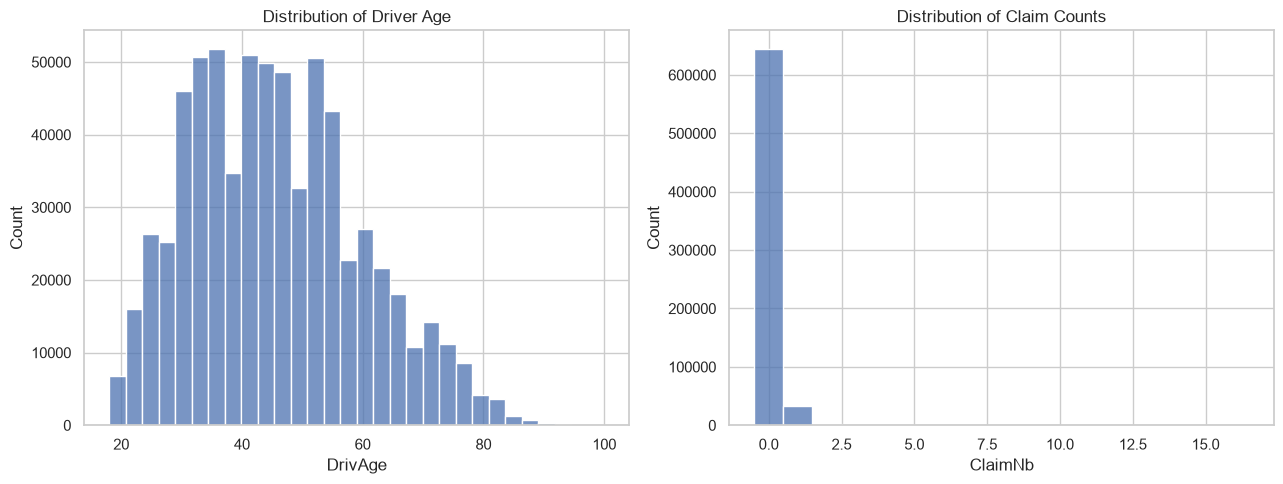

In [5]:
print("Total policies:", len(freq))
print("Total exposure:", freq["Exposure"].sum())
print("Policies with zero claims:",
      (freq["ClaimNb"] == 0).mean() * 100, "%")

print("Overall claim frequency:",
      freq["ClaimNb"].sum() / freq["Exposure"].sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    freq["DrivAge"], bins=30, ax=axes[0]
)
axes[0].set_title("Distribution of Driver Age")

sns.histplot(
    freq["ClaimNb"], discrete=True, ax=axes[1]
)
axes[1].set_title("Distribution of Claim Counts")

plt.tight_layout()
plt.show()

In [6]:
freq["ClaimRate"] = freq["ClaimNb"] / freq["Exposure"]

for col in ["VehAge", "VehPower", "VehGas", "Area"]:
    summary = freq.groupby(col, observed=True).agg(
        Claims=("ClaimNb", "sum"),
        Exposure=("Exposure", "sum")
    )

    summary["Frequency"] = (
        summary["Claims"] / summary["Exposure"]
    )

    print(f"\nClaim frequency by {col}:")
    display(summary.head(20))


Claim frequency by VehAge:


,Claims,Exposure,Frequency
VehAge,,,
0,5205,16719.028729,0.311322
1,2931,32749.537619,0.089497
2,2768,29707.489000,0.093175
3,2320,26081.382861,0.088952
4,2282,23759.975715,0.096044
5,2141,22198.765200,0.096447
6,2117,20788.912907,0.101833
7,1999,19254.174346,0.103822
8,1833,19232.314633,0.095308



Claim frequency by VehPower:


,Claims,Exposure,Frequency
VehPower,,,
4,5699,60073.637304,0.094867
5,7278,68173.348821,0.106757
6,8381,82524.210172,0.101558
7,7627,77950.456700,0.097844
8,1922,22684.616305,0.084727
9,1754,15348.213656,0.114280
10,1789,15375.010824,0.116358
11,897,8497.778452,0.105557
12,359,3792.038343,0.094672



Claim frequency by VehGas:


,Claims,Exposure,Frequency
VehGas,,,
Diesel,16648,170660.893126,0.097550
Regular,19454,187838.552336,0.103568



Claim frequency by Area:


,Claims,Exposure,Frequency
Area,,,
A,5063,61969.377712,0.081702
B,3800,43012.323931,0.088347
C,9875,104449.003784,0.094544
D,8428,77120.191692,0.109284
E,7805,63819.314270,0.122298
F,1131,8129.234074,0.139127


In [8]:
freq_model = freq.loc[
    freq["Exposure"].gt(0)
    & freq["ClaimNb"].ge(0)
    & freq["ClaimNb"].notna()
].copy()

# Keep positive, observed claim amounts
sev_model = sev.loc[
    sev["ClaimAmount"].gt(0)
    & sev["ClaimAmount"].notna()
].copy()

print("Frequency modelling rows:", len(freq_model))
print("Severity modelling rows:", len(sev_model))

Frequency modelling rows: 678013
Severity modelling rows: 26639


In [9]:
severity_data = sev_model.merge(
    freq_model,
    on="IDpol",
    how="inner",
    validate="many_to_one"
)

print("Matched claim records:", len(severity_data))
display(severity_data.head())

Matched claim records: 26444


,IDpol,ClaimAmount,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region,ClaimRate
0,1552,995.20,2,0.59,11,0,39,56,B12,Diesel,D,778,Picardie,3.389831
1,1010996,1128.12,1,0.95,4,1,49,50,B12,Regular,E,2354,Ile-de-France,1.052632
2,4024277,1851.11,1,0.71,4,2,32,106,B12,Regular,D,570,Nord-Pas-de-Calais,1.408451
3,4007252,1204.00,1,0.78,4,1,49,57,B12,Regular,C,288,Midi-Pyrenees,1.282051
4,4046424,1204.00,1,0.86,12,0,37,50,B12,Diesel,F,27000,Ile-de-France,1.162791


In [10]:
duplicate_claims = sev[
    sev.duplicated(keep=False)
].sort_values(["IDpol", "ClaimAmount"])

print("Rows belonging to duplicated claim records:",
      len(duplicate_claims))

display(duplicate_claims.head(20))


claims_per_policy = (
    sev.groupby("IDpol")
       .size()
       .rename("SeverityClaimCount")
       .reset_index()
)

print("Unique policy IDs in severity data:",
      sev["IDpol"].nunique())

print("\nDistribution of severity claim counts:")
display(
    claims_per_policy["SeverityClaimCount"]
    .value_counts()
    .sort_index()
)


claim_comparison = freq[
    ["IDpol", "ClaimNb"]
].merge(
    claims_per_policy,
    on="IDpol",
    how="left",
    validate="one_to_one"
)

claim_comparison["SeverityClaimCount"] = (
    claim_comparison["SeverityClaimCount"].fillna(0).astype(int)
)

claim_comparison["Difference"] = (
    claim_comparison["ClaimNb"]
    - claim_comparison["SeverityClaimCount"]
)

print("Policies with different claim counts:",
      (claim_comparison["Difference"] != 0).sum())

print("\nPolicies where ClaimNb exceeds severity records:")
display(
    claim_comparison[
        claim_comparison["Difference"] > 0
    ].head(10)
)

print("\nPolicies where severity records exceed ClaimNb:")
display(
    claim_comparison[
        claim_comparison["Difference"] < 0
    ].head(10)
)


unmatched_claims = sev[
    ~sev["IDpol"].isin(freq["IDpol"])
]

print("Unmatched severity records:", len(unmatched_claims))
display(unmatched_claims.head(10))

Rows belonging to duplicated claim records: 496


,IDpol,ClaimAmount
5022,18698,1128.12
6355,18698,1128.12
4514,19887,1128.12
4521,19887,1128.12
6318,24992,1128.12
6322,24992,1128.12
5862,25763,1128.12
5866,25763,1128.12
24094,29567,1128.12
24096,29567,1128.12


Unique policy IDs in severity data: 24950

Distribution of severity claim counts:


SeverityClaimCount
1     23571
2      1298
3        62
4         5
5         2
6         1
8         1
9         1
11        2
16        1
21        1
23        1
24        1
25        1
36        1
66        1
Name: count, dtype: int64

Policies with different claim counts: 9117

Policies where ClaimNb exceeds severity records:


,IDpol,ClaimNb,SeverityClaimCount,Difference
0,1.0,1,0,1
1,3.0,1,0,1
2,5.0,1,0,1
3,10.0,1,0,1
4,11.0,1,0,1
5,13.0,1,0,1
6,15.0,1,0,1
7,17.0,1,0,1
8,18.0,1,0,1
9,21.0,1,0,1



Policies where severity records exceed ClaimNb:


,IDpol,ClaimNb,SeverityClaimCount,Difference


Unmatched severity records: 195


,IDpol,ClaimAmount
24857,2262511,2341.37
24858,2262511,1500.00
24863,2262511,135.97
24864,2262511,1500.00
24865,2262511,19461.00
24866,2262511,230.00
24870,2262511,1500.00
24871,2262511,10000.00
24875,2262511,2000.00
24892,2262511,2898.97


In [12]:
exact_duplicates = sev.duplicated(
    subset=["IDpol", "ClaimAmount"],
    keep=False
)

print("Rows involved in repeated IDpol–ClaimAmount pairs:",
      exact_duplicates.sum())

print("Extra rows if one copy of each repeated pair were removed:",
      sev.duplicated(
          subset=["IDpol", "ClaimAmount"],
          keep="first"
      ).sum())


print("\nClaim-count difference distribution:")
display(
    claim_comparison["Difference"]
    .value_counts()
    .sort_index()
    .rename_axis("ClaimNb minus SeverityClaimCount")
    .to_frame("Number of policies")
)


print("\nPolicies with the highest severity-record counts:")
display(
    claim_comparison
    .sort_values("SeverityClaimCount", ascending=False)
    [["IDpol", "ClaimNb", "SeverityClaimCount", "Difference"]]
    .head(15)
)


print("\nMost frequently repeated IDpol–ClaimAmount pairs:")
display(
    sev.groupby(["IDpol", "ClaimAmount"])
       .size()
       .reset_index(name="RecordCount")
       .query("RecordCount > 1")
       .sort_values("RecordCount", ascending=False)
       .head(20)
)

Rows involved in repeated IDpol–ClaimAmount pairs: 496
Extra rows if one copy of each repeated pair were removed: 255

Claim-count difference distribution:


,Number of policies
ClaimNb minus SeverityClaimCount,
0,668896
1,8609
2,485
3,20
4,2
11,1



Policies with the highest severity-record counts:


,IDpol,ClaimNb,SeverityClaimCount,Difference
321248,2241683.0,16,16,0
487268,3253234.0,11,11,0
488270,3254353.0,11,11,0
321512,2248174.0,9,9,0
320764,2239279.0,8,8,0
304484,2216294.0,6,6,0
46470,93954.0,5,5,0
344616,2277762.0,5,5,0
25347,54009.0,4,4,0
655365,6059824.0,4,4,0



Most frequently repeated IDpol–ClaimAmount pairs:


,IDpol,ClaimAmount,RecordCount
15242,2262511,1500.00,6
15792,2282134,1500.00,4
2478,93954,1128.12,4
20538,3253234,1500.00,3
21838,4126439,1204.00,3
14888,2227533,1500.00,3
15667,2277762,1500.00,3
24452,4186720,1204.00,3
15804,2282134,10000.00,3
177,19887,1128.12,2


In [13]:
sev_clean = sev.drop_duplicates(
    subset=["IDpol", "ClaimAmount"],
    keep="first"
).copy()

print("Original severity records:", len(sev))
print("Severity records after deduplication:", len(sev_clean))
print("Rows removed:", len(sev) - len(sev_clean))
print("Remaining duplicate pairs:",
      sev_clean.duplicated(
          subset=["IDpol", "ClaimAmount"]
      ).sum())

Original severity records: 26639
Severity records after deduplication: 26384
Rows removed: 255
Remaining duplicate pairs: 0


In [14]:
sev_model = sev_clean.loc[
    sev_clean["ClaimAmount"].gt(0)
    & sev_clean["ClaimAmount"].notna()
].copy()

severity_data = sev_model.merge(
    freq_model,
    on="IDpol",
    how="inner",
    validate="many_to_one"
)

print("Cleaned severity records:", len(sev_model))
print("Matched severity records:", len(severity_data))
print("Unmatched records excluded:",
      len(sev_model) - len(severity_data))

Cleaned severity records: 26384
Matched severity records: 26209
Unmatched records excluded: 175


In [15]:
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

frequency_formula = """
ClaimNb ~ C(VehPower)
        + C(VehAge)
        + C(DrivAge)
        + BonusMalus
        + C(VehBrand)
        + C(VehGas)
        + C(Area)
        + np.log(Density)
        + C(Region)
"""

frequency_model = smf.glm(
    formula=frequency_formula,
    data=freq_model,
    family=sm.families.Poisson(),
    offset=np.log(freq_model["Exposure"])
).fit()

print(frequency_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               678013
Model:                            GLM   Df Residuals:                   677804
Model Family:                 Poisson   Df Model:                          208
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.4094e+05
Date:                Sun, 25 Oct 2026   Deviance:                   2.1256e+05
Time:                        02:27:43   Pearson chi2:                 1.60e+06
No. Iterations:                    23   Pseudo R-squ. (CS):            0.01743
Covariance Type:            nonrobust                                         
                                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

In [16]:
frequency_results = pd.DataFrame({
    "Coefficient": frequency_model.params,
    "Std_Error": frequency_model.bse,
    "P_value": frequency_model.pvalues
})

frequency_results["Frequency_Relativity"] = np.exp(
    frequency_results["Coefficient"]
)

frequency_results["Change_Percent"] = (
    frequency_results["Frequency_Relativity"] - 1
) * 100

display(
    frequency_results.sort_values("P_value")
)

,Coefficient,Std_Error,P_value,Frequency_Relativity,Change_Percent
C(VehAge)[T.1],-1.234153,0.023123,0.000000,2.910812e-01,-70.891879
C(VehAge)[T.2],-1.170401,0.023706,0.000000,3.102424e-01,-68.975758
C(VehAge)[T.3],-1.210232,0.025352,0.000000,2.981282e-01,-70.187176
C(VehAge)[T.4],-1.136702,0.025780,0.000000,3.208756e-01,-67.912441
C(VehAge)[T.8],-1.152827,0.028511,0.000000,3.157429e-01,-68.425711
...,...,...,...,...,...
C(VehAge)[T.62],-25.017945,366926.680788,0.999946,1.364095e-11,-100.000000
C(VehAge)[T.55],-24.236062,366966.146539,0.999947,2.981343e-11,-100.000000
C(VehAge)[T.71],-23.775131,366944.385456,0.999948,4.727067e-11,-100.000000
C(VehAge)[T.76],-23.149903,366918.937504,0.999950,8.833338e-11,-100.000000


In [19]:
freq_model["DrivAgeGroup"] = pd.cut(
    freq_model["DrivAge"],
    bins=[17, 25, 35, 45, 60, 75, float("inf")],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-60",
        "61-75",
        "Over 75"
    ],
    include_lowest=True
)

display(
    freq_model["DrivAgeGroup"]
    .value_counts()
    .sort_index()
)

DrivAgeGroup
18-25       38895
26-35      149183
36-45      170352
46-60      216355
61-75       84284
Over 75     18944
Name: count, dtype: int64

In [20]:
print("Minimum driver age:", freq_model["DrivAge"].min())
print("Maximum driver age:", freq_model["DrivAge"].max())
print("Driver ages below 18:",
      (freq_model["DrivAge"] < 18).sum())

Minimum driver age: 18
Maximum driver age: 100
Driver ages below 18: 0


In [22]:
frequency_formula_grouped = """
ClaimNb ~ C(VehPower)
        + C(VehAge)
        + C(DrivAgeGroup)
        + BonusMalus
        + C(VehBrand)
        + C(VehGas)
        + C(Area)
        + np.log(Density)
        + C(Region)
"""

frequency_model_grouped = smf.glm(
    formula=frequency_formula_grouped,
    data=freq_model,
    family=sm.families.Poisson(),
    offset=np.log(freq_model["Exposure"])
).fit()

print(frequency_model_grouped.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               678013
Model:                            GLM   Df Residuals:                   677881
Model Family:                 Poisson   Df Model:                          131
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.4115e+05
Date:                Sun, 25 Oct 2026   Deviance:                   2.1298e+05
Time:                        02:41:00   Pearson chi2:                 1.60e+06
No. Iterations:                    23   Pseudo R-squ. (CS):            0.01682
Covariance Type:            nonrobust                                         
                                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

In [23]:
freq_model["VehAgeGroup"] = pd.cut(
    freq_model["VehAge"],
    bins=[-1, 0, 2, 5, 10, 20, float("inf")],
    labels=[
        "0 years",
        "1-2 years",
        "3-5 years",
        "6-10 years",
        "11-20 years",
        "Over 20 years"
    ]
)

display(freq_model["VehAgeGroup"].value_counts().sort_index())

VehAgeGroup
0 years           57739
1-2 years        130408
3-5 years        132490
6-10 years       171594
11-20 years      177460
Over 20 years      8322
Name: count, dtype: int64

In [24]:
frequency_formula_grouped = """
ClaimNb ~ C(VehPower)
        + C(VehAgeGroup)
        + C(DrivAgeGroup)
        + BonusMalus
        + C(VehBrand)
        + C(VehGas)
        + C(Area)
        + np.log(Density)
        + C(Region)
"""

frequency_model_grouped = smf.glm(
    formula=frequency_formula_grouped,
    data=freq_model,
    family=sm.families.Poisson(),
    offset=np.log(freq_model["Exposure"])
).fit()

print(frequency_model_grouped.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               678013
Model:                            GLM   Df Residuals:                   677953
Model Family:                 Poisson   Df Model:                           59
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.4128e+05
Date:                Sun, 25 Oct 2026   Deviance:                   2.1324e+05
Time:                        02:43:13   Pearson chi2:                 1.59e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01645
Covariance Type:            nonrobust                                         
                                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

In [26]:
severity_data["DrivAgeGroup"] = pd.cut(
    severity_data["DrivAge"],
    bins=[17, 25, 35, 45, 60, 75, float("inf")],
    labels=["18-25", "26-35", "36-45", "46-60", "61-75", "Over 75"],
    include_lowest=True
)

severity_data["VehAgeGroup"] = pd.cut(
    severity_data["VehAge"],
    bins=[-1, 0, 2, 5, 10, 20, float("inf")],
    labels=[
        "0 years", "1-2 years", "3-5 years",
        "6-10 years", "11-20 years", "Over 20 years"
    ]
)

print("Driver-age groups created:",
      severity_data["DrivAgeGroup"].notna().sum())
print("Vehicle-age groups created:",
      severity_data["VehAgeGroup"].notna().sum())

Driver-age groups created: 26209
Vehicle-age groups created: 26209


In [27]:
severity_formula = """
ClaimAmount ~ C(VehPower)
            + C(VehAgeGroup)
            + C(DrivAgeGroup)
            + BonusMalus
            + C(VehBrand)
            + C(VehGas)
            + C(Area)
            + np.log(Density)
            + C(Region)
"""

severity_model = smf.glm(
    formula=severity_formula,
    data=severity_data,
    family=sm.families.Gamma(
        link=sm.families.links.Log()
    )
).fit()

print(severity_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:            ClaimAmount   No. Observations:                26209
Model:                            GLM   Df Residuals:                    26149
Model Family:                   Gamma   Df Model:                           59
Link Function:                    Log   Scale:                          29.469
Method:                          IRLS   Log-Likelihood:            -2.7219e+05
Date:                Sun, 25 Oct 2026   Deviance:                       41824.
Time:                        02:49:58   Pearson chi2:                 7.71e+05
No. Iterations:                    75   Pseudo R-squ. (CS):           0.005893
Covariance Type:            nonrobust                                         
                                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

In [28]:
print("Converged:", severity_model.converged)

severity_results = pd.DataFrame({
    "Coefficient": severity_model.params,
    "Std_Error": severity_model.bse,
    "P_value": severity_model.pvalues
})

severity_results["Severity_Relativity"] = np.exp(
    severity_results["Coefficient"]
)

severity_results["Change_Percent"] = (
    severity_results["Severity_Relativity"] - 1
) * 100

display(severity_results.round(4))

Converged: True


,Coefficient,Std_Error,P_value,Severity_Relativity,Change_Percent
Intercept,7.3050,0.7031,0.0000,1487.7364,148673.6362
C(VehPower)[T.5],-0.1720,0.1193,0.1494,0.8419,-15.8063
C(VehPower)[T.6],0.0577,0.1168,0.6212,1.0594,5.9408
C(VehPower)[T.7],-0.0222,0.1154,0.8477,0.9781,-2.1923
C(VehPower)[T.8],-0.1417,0.1651,0.3907,0.8679,-13.2091
C(VehPower)[T.9],0.3300,0.1807,0.0678,1.3910,39.0987
C(VehPower)[T.10],0.0867,0.1834,0.6367,1.0905,9.0515
C(VehPower)[T.11],-0.1038,0.2261,0.6461,0.9014,-9.8582
C(VehPower)[T.12],0.2576,0.3360,0.4432,1.2939,29.3852
C(VehPower)[T.13],-0.0630,0.4818,0.8960,0.9390,-6.1041


In [29]:
print("Grouped frequency model converged:",
      frequency_model_grouped.converged)

print("Frequency model iterations:",
      frequency_model_grouped.fit_history.get("iteration"))

print("\nSeverity model converged:",
      severity_model.converged)

Grouped frequency model converged: True
Frequency model iterations: 7

Severity model converged: True


In [30]:
pricing_data = freq_model.copy()

pricing_data["Predicted_Claim_Count"] = (
    frequency_model_grouped.predict(
        pricing_data,
        offset=np.log(pricing_data["Exposure"])
    )
)

pricing_data["Predicted_Frequency"] = (
    pricing_data["Predicted_Claim_Count"]
    / pricing_data["Exposure"]
)

pricing_data["Predicted_Severity"] = severity_model.predict(
    pricing_data
)

pricing_data["Pure_Risk_Premium"] = (
    pricing_data["Predicted_Frequency"]
    * pricing_data["Predicted_Severity"]
)

display(
    pricing_data[
        [
            "IDpol",
            "Exposure",
            "Predicted_Frequency",
            "Predicted_Severity",
            "Pure_Risk_Premium"
        ]
    ].head(10).round(2)
)

print("\nSummary of predicted annual pure risk premiums:")
display(pricing_data["Pure_Risk_Premium"].describe().round(2))

,IDpol,Exposure,Predicted_Frequency,Predicted_Severity,Pure_Risk_Premium
0,1.0,0.10,0.37,1825.89,680.51
1,3.0,0.77,0.37,1825.89,680.51
2,5.0,0.75,0.09,2398.53,220.77
3,10.0,0.09,0.25,1858.72,458.09
4,11.0,0.84,0.25,1858.72,458.09
5,13.0,0.52,0.08,1874.78,155.22
6,15.0,0.45,0.08,1874.78,155.22
7,17.0,0.27,0.27,1744.40,477.08
8,18.0,0.71,0.27,1744.40,477.08
9,21.0,0.15,0.23,1603.00,375.63



Summary of predicted annual pure risk premiums:


count    678013.00
mean        255.34
std         285.84
min          22.71
25%         126.53
50%         168.46
75%         263.91
max       22055.50
Name: Pure_Risk_Premium, dtype: float64

In [32]:
observed_claims = (
    severity_data.groupby("IDpol")["ClaimAmount"]
    .sum()
    .rename("Observed_Claim_Cost")
    .reset_index()
)

validation_data = pricing_data.merge(
    observed_claims,
    on="IDpol",
    how="left",
    validate="one_to_one"
)

validation_data["Observed_Claim_Cost"] = (
    validation_data["Observed_Claim_Cost"].fillna(0)
)

print("Policies in validation dataset:", len(validation_data))
print("Policies with positive recorded claim cost:",
      (validation_data["Observed_Claim_Cost"] > 0).sum())

display(
    validation_data[
        [
            "IDpol",
            "Exposure",
            "Observed_Claim_Cost",
            "Pure_Risk_Premium"
        ]
    ].head(10).round(2)
)

Policies in validation dataset: 678013
Policies with positive recorded claim cost: 24944


,IDpol,Exposure,Observed_Claim_Cost,Pure_Risk_Premium
0,1.0,0.10,0.0,680.51
1,3.0,0.77,0.0,680.51
2,5.0,0.75,0.0,220.77
3,10.0,0.09,0.0,458.09
4,11.0,0.84,0.0,458.09
5,13.0,0.52,0.0,155.22
6,15.0,0.45,0.0,155.22
7,17.0,0.27,0.0,477.08
8,18.0,0.71,0.0,477.08
9,21.0,0.15,0.0,375.63


In [33]:
total_exposure = validation_data["Exposure"].sum()

observed_cost_per_vehicle_year = (
    validation_data["Observed_Claim_Cost"].sum()
    / total_exposure
)

predicted_cost_per_vehicle_year = (
    validation_data["Pure_Risk_Premium"]
    * validation_data["Exposure"]
).sum() / total_exposure

print(f"Total exposure: {total_exposure:,.2f} vehicle-years")
print(f"Observed cost per vehicle-year: "
      f"{observed_cost_per_vehicle_year:,.2f}")
print(f"Predicted cost per vehicle-year: "
      f"{predicted_cost_per_vehicle_year:,.2f}")
print(f"Difference: "
      f"{predicted_cost_per_vehicle_year - observed_cost_per_vehicle_year:,.2f}")

Total exposure: 358,499.45 vehicle-years
Observed cost per vehicle-year: 166.34
Predicted cost per vehicle-year: 222.23
Difference: 55.89


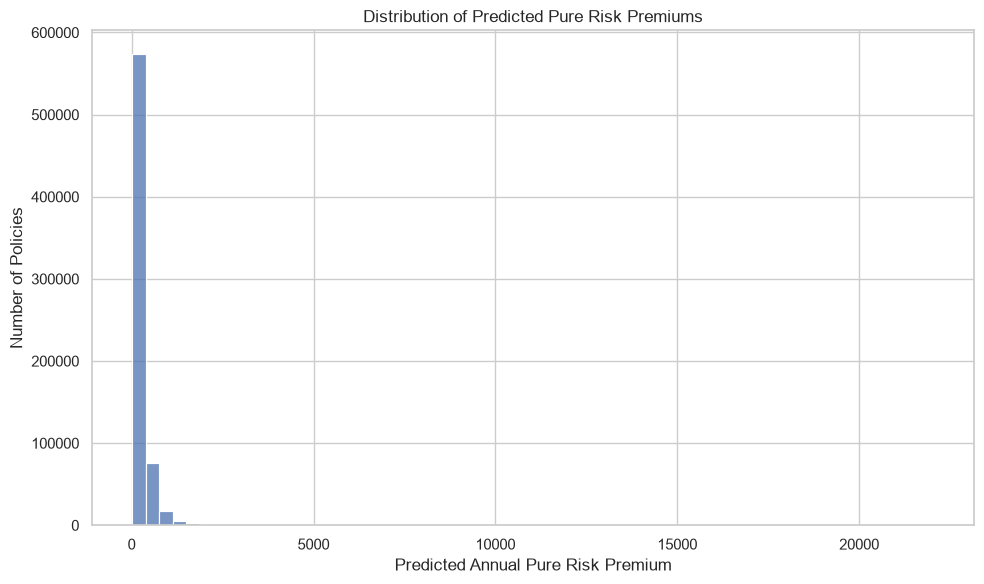

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.histplot(
    data=pricing_data,
    x="Pure_Risk_Premium",
    bins=60
)

plt.title("Distribution of Predicted Pure Risk Premiums")
plt.xlabel("Predicted Annual Pure Risk Premium")
plt.ylabel("Number of Policies")
plt.tight_layout()
plt.show()

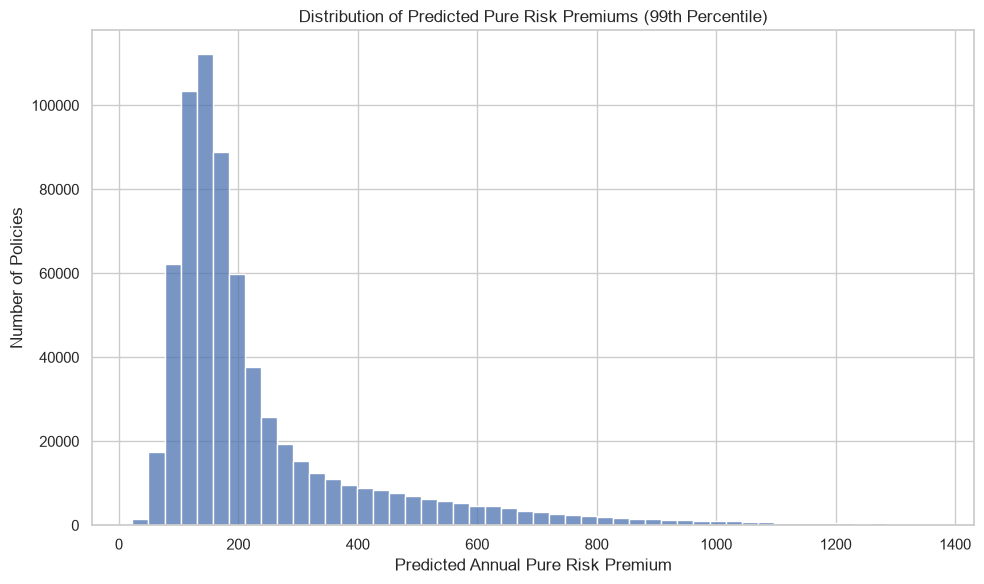

99th percentile: 1364.66
All observations remain in pricing_data.


In [35]:
premium_99 = pricing_data["Pure_Risk_Premium"].quantile(0.99)

plt.figure(figsize=(10, 6))

sns.histplot(
    data=pricing_data[
        pricing_data["Pure_Risk_Premium"] <= premium_99
    ],
    x="Pure_Risk_Premium",
    bins=50
)

plt.title("Distribution of Predicted Pure Risk Premiums (99th Percentile)")
plt.xlabel("Predicted Annual Pure Risk Premium")
plt.ylabel("Number of Policies")
plt.tight_layout()
plt.show()

print(f"99th percentile: {premium_99:.2f}")
print("All observations remain in pricing_data.")

,DrivAgeGroup,Observed_Claims,Exposure,Predicted_Claims,Observed_Frequency,Predicted_Frequency
0,18-25,2841,16227.9033,2841.0,0.1751,0.1751
1,26-35,6662,69266.7781,6662.0,0.0962,0.0962
2,36-45,8397,87702.3363,8397.0,0.0957,0.0957
3,46-60,12013,120014.3647,12013.0,0.1001,0.1001
4,61-75,4864,51796.9585,4864.0,0.0939,0.0939
5,Over 75,1325,13491.1047,1325.0,0.0982,0.0982


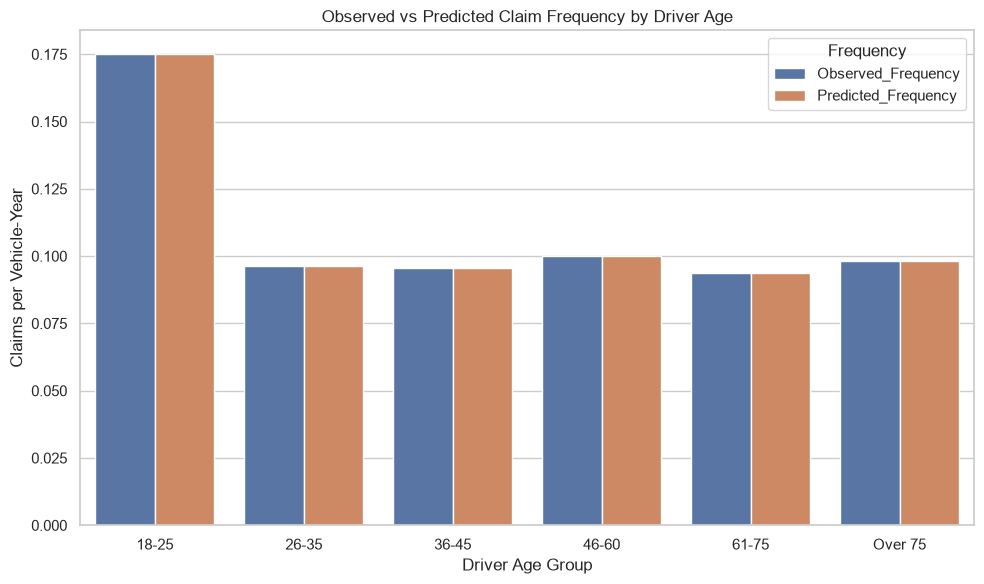

In [36]:
age_validation = pricing_data.groupby(
    "DrivAgeGroup", observed=False
).agg(
    Observed_Claims=("ClaimNb", "sum"),
    Exposure=("Exposure", "sum"),
    Predicted_Claims=("Predicted_Claim_Count", "sum")
).reset_index()

age_validation["Observed_Frequency"] = (
    age_validation["Observed_Claims"] / age_validation["Exposure"]
)

age_validation["Predicted_Frequency"] = (
    age_validation["Predicted_Claims"] / age_validation["Exposure"]
)

display(age_validation.round(4))

age_plot = age_validation.melt(
    id_vars="DrivAgeGroup",
    value_vars=["Observed_Frequency", "Predicted_Frequency"],
    var_name="Frequency_Type",
    value_name="Claims_Per_Vehicle_Year"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_plot,
    x="DrivAgeGroup",
    y="Claims_Per_Vehicle_Year",
    hue="Frequency_Type"
)

plt.title("Observed vs Predicted Claim Frequency by Driver Age")
plt.xlabel("Driver Age Group")
plt.ylabel("Claims per Vehicle-Year")
plt.legend(title="Frequency")
plt.tight_layout()
plt.show()

,Driver Age Group,Frequency Relativity,Severity Relativity
0,26-35,0.853,0.514
1,36-45,1.102,0.488
2,46-60,1.233,0.493
3,61-75,1.176,0.570
4,Over 75,1.285,0.639


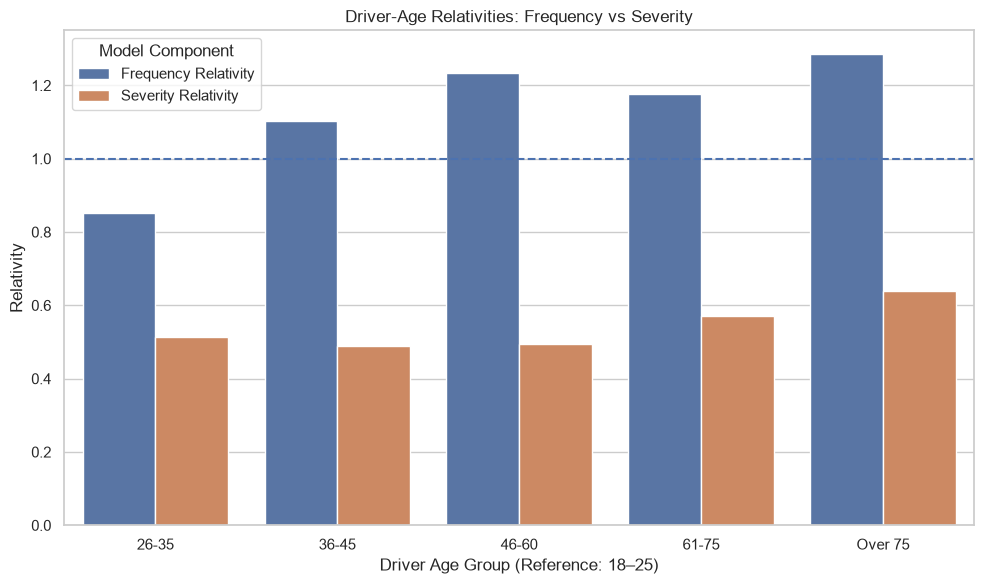

In [37]:
age_groups = [
    "26-35", "36-45", "46-60", "61-75", "Over 75"
]

frequency_age = []
severity_age = []

for age in age_groups:
    freq_term = f"C(DrivAgeGroup)[T.{age}]"
    sev_term = f"C(DrivAgeGroup)[T.{age}]"

    frequency_age.append(
        np.exp(frequency_model_grouped.params[freq_term])
    )
    severity_age.append(
        np.exp(severity_model.params[sev_term])
    )

relativity_data = pd.DataFrame({
    "Driver Age Group": age_groups,
    "Frequency Relativity": frequency_age,
    "Severity Relativity": severity_age
})

display(relativity_data.round(3))

relativity_plot = relativity_data.melt(
    id_vars="Driver Age Group",
    var_name="Model Component",
    value_name="Relativity"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=relativity_plot,
    x="Driver Age Group",
    y="Relativity",
    hue="Model Component"
)

plt.axhline(1, linestyle="--")
plt.title("Driver-Age Relativities: Frequency vs Severity")
plt.xlabel("Driver Age Group (Reference: 18–25)")
plt.ylabel("Relativity")
plt.tight_layout()
plt.show()